# Segment water in GDL to quantify influence of liquid water on electrochemistry

TODO:

- [ ] select only the data containing the GDL and channels
- [ ] set up ML and train on one sample
- [ ] apply classfier to test sample and segment all
    - [ ] align samples with new cropping --> can be independent of membrane segmentation

In [126]:
# modules
import os
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import dask
import dask.array
from scipy import ndimage
from skimage import filters, feature, io
from skimage.morphology import disk,ball
import sys
from itertools import combinations_with_replacement
import pickle
import imageio
import json
from dask.distributed import Client, LocalCluster

# Workaround that dask does not kill workers while they are busy fetching data: https://dask.discourse.group/t/dask-workers-killed-because-of-heartbeat-fail/856
# maybe this helps: https://www.youtube.com/watch?v=vF2VItVU5zg?
from dask import config as cfg
cfg.set({'distributed.scheduler.worker-ttl': None})

# get the ML functions, TODO: make a library once it works
pytrainpath = '/mpc/homes/fische_r/lib/pytrainseg'
cwd = os.getcwd()
os.chdir(pytrainpath)
from filter_functions import image_filter
import training_functions as tfs
from training_functions import train_segmentation
from segmentation import segmentation
os.chdir(cwd)

#paths
import socket
import subprocess
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'
    temppath = '/mnt/SSD/fische_r/tmp'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'
else:
    print('currently only host mpc2959.psi.ch supported')
    
path_02_4D = os.path.join(toppathSSD, '02_registered_3p1D') #h5 with registered data

# fetch githash
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)

### functionalities for interactive training

In [2]:
from ipywidgets import Image
from ipywidgets import ColorPicker, IntSlider, link, AppLayout, HBox
from ipycanvas import  hold_canvas,  MultiCanvas #RoughCanvas,Canvas,

def on_mouse_down(x, y):
    global drawing
    global position
    global shape
    drawing = True
    position = (x, y)
    shape = [position]

def on_mouse_move(x, y):
    global drawing
    global position
    global shape
    if not drawing:
        return
    with hold_canvas():
        canvas.stroke_line(position[0], position[1], x, y)
        position = (x, y)
    shape.append(position)

def on_mouse_up(x, y):
    global drawing
    global positiondu
    global shape
    drawing = False
    with hold_canvas():
        canvas.stroke_line(position[0], position[1], x, y)
        canvas.fill_polygon(shape)
    shape = []
    
def display_feature(i, TS):
    print('selected '+TS.feature_names[i])
    im = TS.current_feat_stack[:,:,i]
    im8 = im-im.min()
    im8 = im8/im8.max()*255
    return im8

### fire up dask

In [3]:
tempfolder = temppath  #a big SSD is a major adavantage to allow spill to disk and still be efficient. large dataset mightd crash or be slow with normal HDD
# tempfolder = temppath_2
dask.config.config['temporary-directory'] = tempfolder

# here you have the option to use a virtual cluster or even slurm on ra (not attempted yet)
cluster = LocalCluster(dashboard_address=':35000', memory_limit = '160GB', n_workers=6, threads_per_worker=20) #settings optimised for mpc2959, play arund if needed, 
client = Client(cluster)
print('Dashboard at '+cluster.dashboard_link)

Dashboard at http://127.0.0.1:35000/status


## Test ROI selection

In [4]:
sample = '4'

In [5]:
# file = '01_'+sample+'_rotated_3p1D.nc'
file = '02_'+sample+'_registered_3p1D.nc'
imagepath = os.path.join(path_02_4D, file)
data = xr.open_dataset(imagepath)
images = [im for im in data.keys() if im[3:7] == 'imag']
images.sort()

In [6]:
im300 = data[images[4]][:,:,300].data

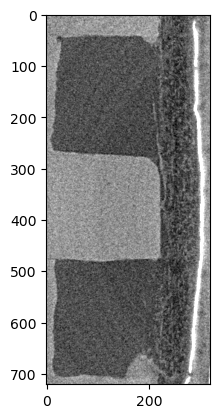

In [21]:
plt.imshow(im300[50:-50,50:370], cmap='gray', vmin=10000, vmax=15000)

In [19]:
data.close()

In [22]:
## individual cropping appears to be require for a good ROI for all samples, use same with and height!!

In [123]:
training_path

'/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'

(942, 652) (750, 340)
(764, 667) (750, 340)
(867, 700) (750, 340)
(821, 698) (750, 340)
(750, 660) (750, 340)
(850, 670) (750, 340)
(860, 660) (750, 340)
(869, 700) (750, 340)
(880, 680) (750, 340)
(750, 680) (750, 340)


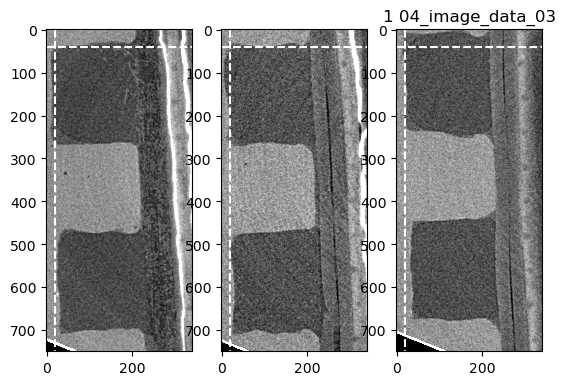

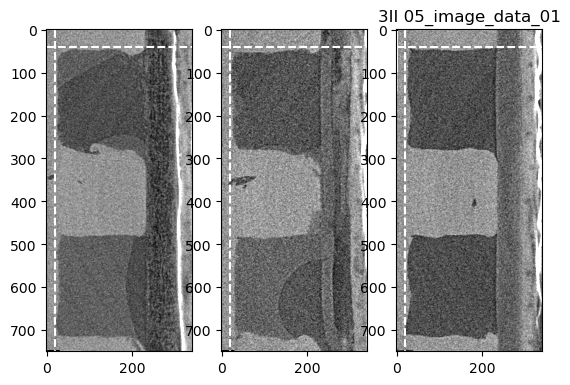

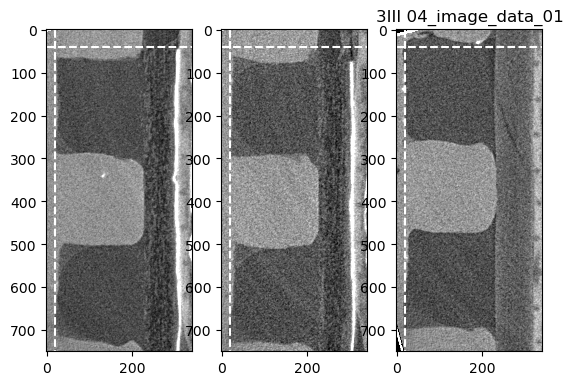

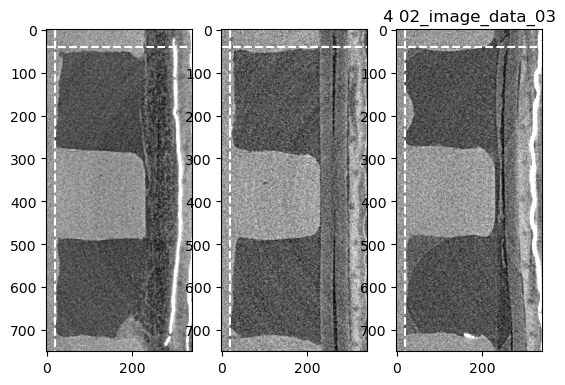

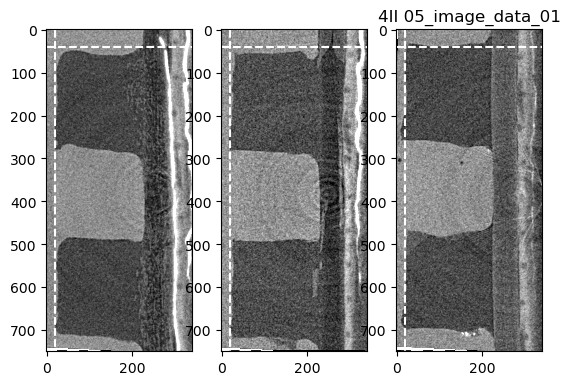

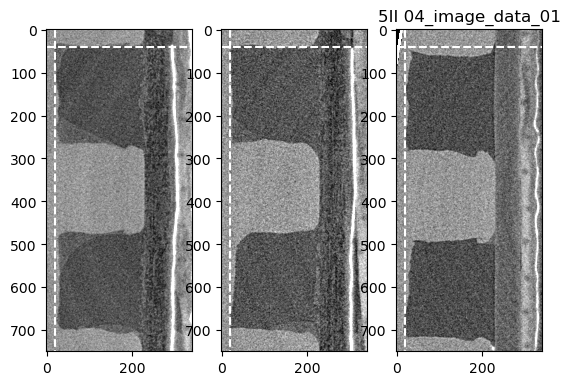

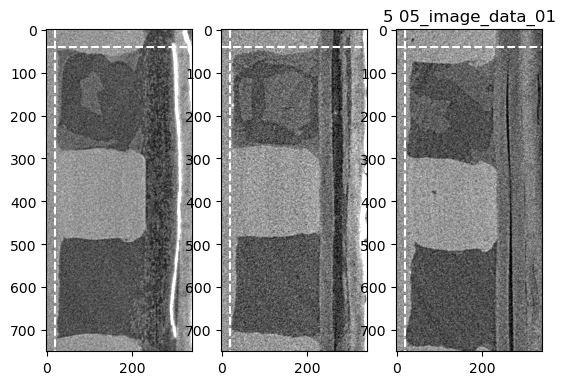

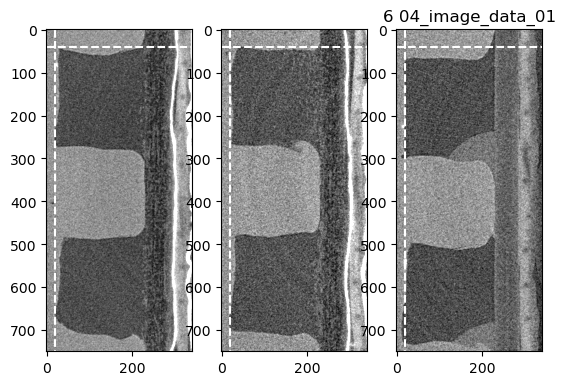

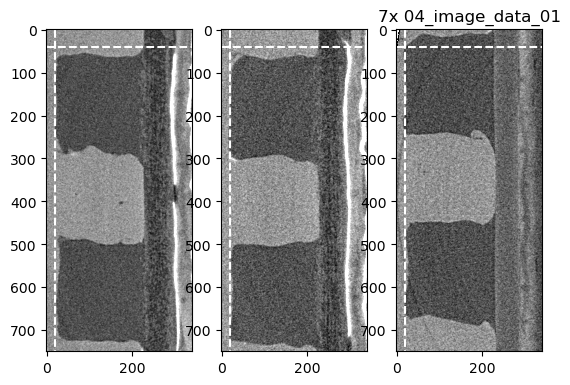

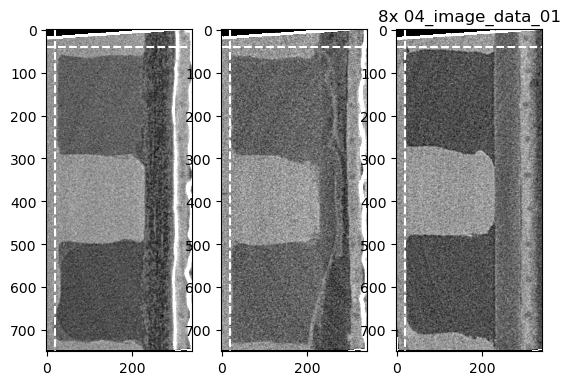

In [127]:
height = 750
width = 340
a = 0
b = a+height
c = 30
d = c + width

crop_dict = {}
crop_dict['1'] = (120, 120+height, 10, 10+width) # sample 1 should be aligned by rotation
crop_dict['3II'] = (5, 5+height, 0, width)
crop_dict['3III'] = (80, 80+height, 20, 20+width)
crop_dict['4'] = (40, 40+height, 40, 40+width)
crop_dict['4II'] = (0, 0+height, 10, 10+width)
crop_dict['5II'] = (25, 25+height, 15, 15+width)
crop_dict['5'] = (57, 57+height, 10, 10+width)
crop_dict['6'] = (105, 105+height, 30, 30+width)
crop_dict['7x'] = (70, 70+height, 15, 15+width)
crop_dict['8x'] = (0, 0+height, 25, 25+width)

samplesall = ['1', '3II', '3III', '4', '4II', '5II', '5', '6', '7x', '8x']

if not os.path.exists(training_path):
    os.mkdir(training_path)

jsonpath = os.path.join(training_path, 'cathode_cropping_and_aligning.json')
with open(jsonpath, "w") as outfile:
    json.dump(crop_dict, outfile,indent = 4)

# samplesall = samplesall[6:10]

for sample in samplesall:
    (a1,b1,c1,d1) = (a,b,c,d)
    if sample in crop_dict.keys():
        (a1,b1,c1,d1) = crop_dict[sample]
    file = '02_'+sample+'_registered_3p1D.nc'
    imagepath = os.path.join(path_02_4D, file)
    data = xr.open_dataset(imagepath)
    images = [im for im in data.keys() if im[3:7] == 'imag']
    images.sort()
    im300 = data[images[6]][:,:,300].data
    im0 = data[images[6]][:,:,50].data
    imfin = data[images[6]][:,:,-50].data
    data.close()
    fig, axs = plt.subplots(1,3)
    axs[0].imshow(im300[a1:b1,c1:d1], cmap='gray', vmin=10000, vmax=15000)
    axs[1].imshow(im0[a1:b1,c1:d1], cmap='gray', vmin=10000, vmax=15000)
    axs[2].imshow(imfin[a1:b1,c1:d1], cmap='gray', vmin=10000, vmax=15000)
    print(imfin.shape, imfin[a1:b1,c1:d1].shape)
    
    for ax in axs:
        ax.vlines(20,0,height-1,'w', linestyle='--')
        ax.hlines(40,0,width-1,'w', linestyle='--')
    
    plt.title(sample +' '+ images[4])
    

## Data preparation

### create dask array

In [128]:
sample = '4'
file = '02_'+sample+'_registered_3p1D.nc'
imagepath = os.path.join(path_02_4D, file)
data = xr.open_dataset(imagepath)
images = [im for im in data.keys() if im[3:7] == 'imag']
images.sort()

In [129]:
t_utc = data['t_utc'].data
time = data['time'].data

In [130]:
# with obtained cropping data
# a = 0
# b = -1
# c = 250
# d = -250
# e = 50
# f = -50
jsonpath = os.path.join(training_path, 'cathode_cropping_and_aligning.json')
crop_dict = json.load(open(jsonpath, 'r'))

(a,b,c,d) = crop_dict[sample]
(e,f) = (50,-50)

shp = data[images[4]][a:b, c:d, e:f].shape
shp = shp + (len(images),)

In [131]:
im = np.zeros(shp, dtype = np.uint16)

In [132]:
# with obtained cropping data
for i in range(shp[-1]):
    im[...,i] = data[images[i]][a:b, c:d, e:f].data

In [133]:
da = dask.array.from_array(im, chunks = 'auto')

In [134]:
del im

In [135]:
da

dask.array<array, shape=(750, 340, 1916, 71), dtype=uint16, chunksize=(98, 98, 98, 71), chunktype=numpy.ndarray>

In [136]:
data.close()

### get data into image filter class

In [137]:
# TODO: include this routine into pytrainseg

IF = image_filter() #default feauture settings sigmas = [0,2, 4],
IF.data = da
shp = da.shape
coords = {'x': np.arange(shp[0]), 'y': np.arange(shp[1]), 'z': np.arange(shp[2]), 'time': np.arange(shp[3])}
IF.original_dataset = xr.Dataset({'tomo': (['x','y','z','time'], da)},
                                 coords = coords
                                )
IF.data = IF.data.rechunk('auto')

### prepare features

In [138]:
IF.prepare()

In [139]:
IF.stack_features()

In [140]:
IF.feature_stack

dask.array<stack, shape=(750, 340, 1916, 71, 67), dtype=float64, chunksize=(64, 64, 64, 64, 1), chunktype=numpy.ndarray>

In [141]:
IF.make_xarray_nc()

## Training

### set up objects

In [142]:
training_path = os.path.join(training_path, sample)
if not os.path.exists(training_path):
    os.mkdir(training_path)

In [143]:
TS = train_segmentation(training_path=training_path)

In [144]:
TS.import_lazy_feature_data(IF.result, IF.original_dataset)

### interactive training

#### check for existing training sets

In [145]:
os.listdir(os.path.join(training_path, 'label_images'))

[]

#### suggest a new training coordinate

In [210]:
TS.suggest_training_set()

You could try  z = 564  and  time = 0
However, please sort it like the original xyztime


In [253]:
c1 = 'y'
p1 = 255
c2 = 'time'
p2 = 20

In [254]:
TS.load_training_set(c1, p1, c2, p2)
im8 = TS.current_im8

#### canvas for labeling

In [283]:
alpha = 0.15

zoom1 = (150,-150)
zoom2 = (600, -500)

# im8 = TS.current_im8
#trick: use gaussian_time_4_0 to label static phases (-13)
# im8 = display_feature(-13, TS)

im8_display = im8.copy()[zoom1[0]:zoom1[1], zoom2[0]:zoom2[1]]

resultim = TS.current_result.copy()

resultim_display = resultim[zoom1[0]:zoom1[1], zoom2[0]:zoom2[1]]


width = im8_display.shape[1]
height = im8_display.shape[0]
Mcanvas = MultiCanvas(4, width=width, height=height)
background = Mcanvas[0]
resultdisplay = Mcanvas[2]
truthdisplay = Mcanvas[1]
canvas = Mcanvas[3]
canvas.sync_image_data = True
drawing = False
position = None
shape = []
image_data = np.stack((im8_display, im8_display, im8_display), axis=2)
background.put_image_data(image_data, 0, 0)
slidealpha = IntSlider(description="Result overlay", value=0.15)
resultdisplay.global_alpha = alpha #slidealpha.value
if np.any(resultim>0):
    result_data = np.stack((255*(resultim_display==0), 255*(resultim_display==1), 255*(resultim_display==2)), axis=2)
else:
    result_data = np.stack((0*resultim, 0*resultim, 0*resultim), axis=2)
resultdisplay.put_image_data(result_data, 0, 0)
canvas.on_mouse_down(on_mouse_down)
canvas.on_mouse_move(on_mouse_move)
canvas.on_mouse_up(on_mouse_up)
picker = ColorPicker(description="Color:", value="#ff0000") #red
# picker = ColorPicker(description="Color:", value="#0000ff") #blue
# picker = ColorPicker(description="Color:", value="#00ff00") #green

link((picker, "value"), (canvas, "stroke_style"))
link((picker, "value"), (canvas, "fill_style"))
link((slidealpha, "value"), (resultdisplay, "global_alpha"))

HBox((Mcanvas,picker))
# HBox((Mcanvas,)) #picker

In [279]:
# tfs.plot_im_histogram(im8)
# im8 = tfs.adjust_image_contrast(TS.current_im8,20,150)

#### inspect labels and training progress

In [236]:
fig, axes = plt.subplots(1,6, figsize=(20,10))
axes[0].imshow(TS.current_result, 'gray')
axes[1].imshow(TS.current_im8, 'gray')

# TS.current_diff_im = TS.current_im-TS.current_first_im
# TS.current_diff_im = TS.current_diff_im/TS.current_diff_im.max()*255
axes[2].imshow(-TS.current_diff_im,vmin=6e4)
# axes[3].imshow(m8old, 'gray')
axes[3].imshow(TS.current_first_im, 'gray')
axes[4].imshow(TS.current_truth)
if TS.current_computed:
    axes[5].imshow(TS.current_feat_stack[:,:,-10])
else:
    axes[5].imshow(TS.current_result, 'gray')

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])

Error in callback <function _draw_all_if_interactive at 0x7fc81f0b78b0> (for post_execute):


ValueError: minvalue must be less than or equal to maxvalue

ValueError: minvalue must be less than or equal to maxvalue

<Figure size 2000x1000 with 6 Axes>

#### update training set if labels are ok

In [284]:
label_set = canvas.get_image_data()

TS.current_truth[zoom1[0]:zoom1[1], zoom2[0]:zoom2[1]][label_set[:,:,0]>0] = 1
TS.current_truth[zoom1[0]:zoom1[1], zoom2[0]:zoom2[1]][label_set[:,:,1]>0] = 2
TS.current_truth[zoom1[0]:zoom1[1], zoom2[0]:zoom2[1]][label_set[:,:,2]>0] = 4

imageio.imsave(TS.current_truthpath, TS.current_truth)

#### train!

In [ ]:
# TODO: see, if training gets slow for many label sets, currently stored in training_dict and read as loop. or if it is just the larger amount of data
TS.train_slice()

training and classifying


In [239]:
# # load exisiting classifier and segment one slice
# clf = pickle.load(open(os.path.join(training_path, 'classifier.p'), 'rb'))
# feat = TS.current_feat_stack.compute()
# shp = feat[...,0].shape
# num_feat = feat.shape[-1]
# feat = feat.reshape(-1,num_feat)
# seg = clf.predict(feat)
# seg = seg.reshape(shp).astype(np.uint8)
# plt.figure(figsize=(16,9))
# plt.imshow(seg, cmap='gray_r')

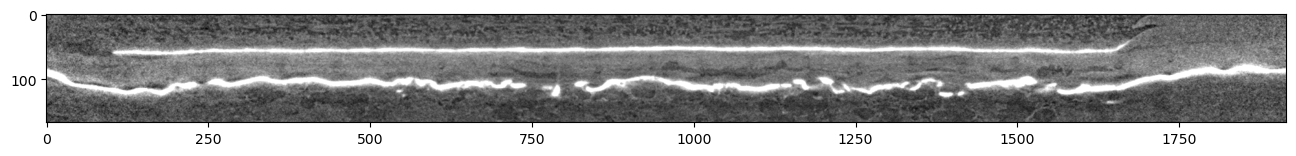

In [47]:
# plt.figure(figsize=(16,9))
# plt.imshow(im8, cmap='gray')

#### go back until happy

#### check on training progress by plausible feature importance

Text(0, 0.5, 'importance')

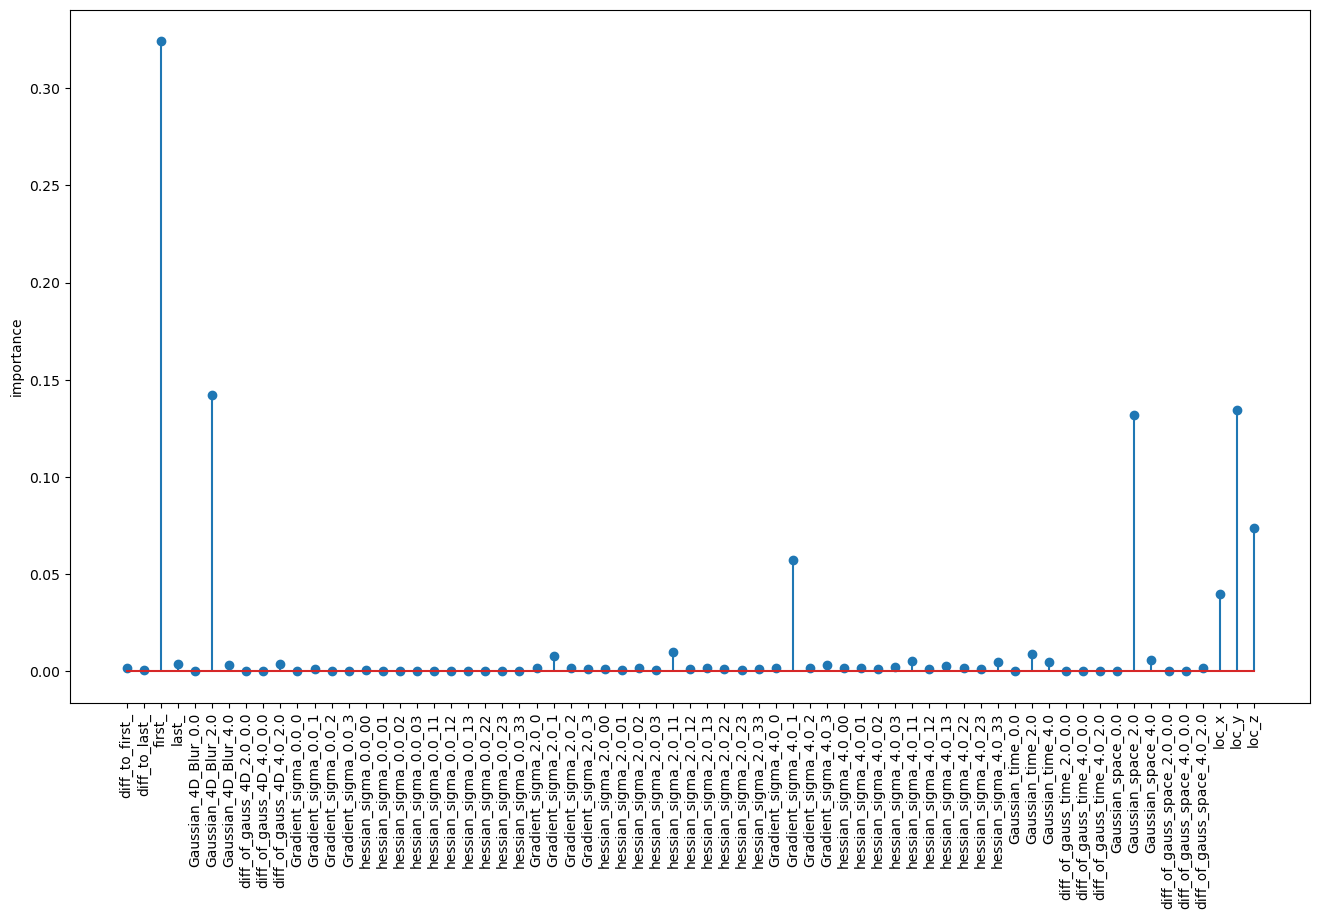

In [437]:
plt.figure(figsize=(16,9))
plt.stem(TS.feature_names, TS.clf.feature_importances_,'x')
plt.xticks(rotation=90)
plt.ylabel('importance') 
# plt.xticks(rotation = 60)

### when done, maybe save the classifier and optional the training dict (avoids recalculating the training sets, but might be large)

In [438]:
# TS.pickle_classifier()
# pickle.dump(TS.training_dict, open(os.path.join(TS.training_path, 'training_dict.p'),'wb'))

## Segmentation of full data set

In [26]:
from segmentation import segmentation

In [27]:
SM = segmentation(training_path = training_path, classifier_path=os.path.join(training_path, 'classifier.p'))

In [28]:
SM.import_lazy_feature_data(IF.result)
# SM.import_classifier(TS.clf)
SM.clf = pickle.load(open(os.path.join(training_path, 'classifier.p'), 'rb'))

In [29]:
clf = SM.clf
clf.n_jobs = 32

In [30]:
#TODO create result as a stream for every feature set of chunks, i.e stack of 67 feature chunks


### check aligment of chunks and select suitable "super-chunk" shape to split calculation in parts, example below

In [31]:
feat = IF.feature_stack

In [32]:
feat

dask.array<stack, shape=(764, 167, 1916, 63, 67), dtype=float64, chunksize=(64, 64, 64, 63, 1), chunktype=numpy.ndarray>

In [33]:
i = 5
dim1 = 120
dim2 = int(2.5*dim1)
feat[i*dim1:(i+1)*dim1,:,i*dim2:(i+1)*dim2,:,:] #select all features and all time steps, but you are free in space; als large as possible and as small as necessary. limit is the available RAM to collect the dask result

dask.array<getitem, shape=(120, 167, 300, 63, 67), dtype=float64, chunksize=(64, 64, 64, 63, 1), chunktype=numpy.ndarray>

In [41]:
segs = np.zeros(feat.shape[:4], dtype=np.uint8)

In [ ]:
limit = 7

for i in range(limit):
    print(str(i+1)+'/'+str(limit))
    plt.figure()
    plt.imshow(segs[:,100,:, 50])
    plt.savefig(os.path.join(training_path, str(i)+'_progress.png'))
    for j in range(limit):

        part = feat[i*dim1:(i+1)*dim1,:,j*dim2:(j+1)*dim2,:,:].compute()
        shp = part.shape
        num_feat = part.shape[-1]  
        part = part.reshape(-1,num_feat)

        psplit = int(part.shape[0]/2)
        print('segmenting')
        part1 = part[:psplit,:].copy()
        part2 = part[psplit:,:].copy()
        del part

        #is it necessary to do the astype?
        seg1 = clf.predict(part1).astype(np.uint8)
        del part1

        seg2 = clf.predict(part2).astype(np.uint8)
        del part2

        seg = np.concatenate([seg1,seg2])
        print(seg.shape)
        del seg1
        del seg2

        seg = seg.reshape(shp[:4])  #this step needs a lot of RAM ?!
    
    # not sure if this switch cases are necessary
        if i < limit-1 and j < limit-1:
            segs[i*dim1:(i+1)*dim1,:,j*dim2:(j+1)*dim2,:] = seg
        elif not i < limit-1 and j < limit-1:
            segs[i*dim1:,:,j*dim2:(j+1)*dim2,:] =  seg
        elif not j < limit-1 and i < limit-1:
            segs[i*dim1:(i+1)*dim1,:,j*dim2:,:] =  seg
        else:
            segs[i*dim1:,:,j*dim2:,:] = seg
            
        del seg

4/7
(378756000, 67)
segmenting
a
b
c
1
2
3
(378756000, 67)
segmenting
a
b


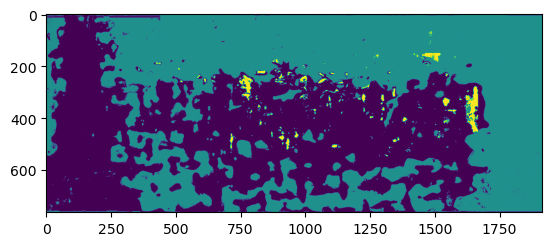

In [50]:
plt.imshow(segs[:,100,:, 50])

### save result to disk

In [41]:
path = os.path.join(training_path, 'segmented.nc')
shp = segs.shape
segdata = xr.Dataset({'segmented': (['x','y','z','time'], segs)},
                               coords = {'x': np.arange(shp[0]),
                               'y': np.arange(shp[1]),
                               'z': np.arange(shp[2]),
                               'time': np.arange(shp[3]),
                               'feature': SM.feature_names},
                     attrs = {'name': sample,
                             'cropping': [a,b,c,d,e,f]}
                     )

In [43]:
segpath = os.path.join(training_path, 'final_seg.nc')

In [44]:
# segdata.to_netcdf(segpath)

In [36]:
# load intermediate result
seg_data = xr.load_dataset(segpath)

In [37]:
segs = seg_data['segmented'].data

In [31]:
# del seg_data